# 04 — Clustering des pays

**Entrée** : `data/processed/co2_clean.csv`  
Regroupement des pays par K-Means (standardisation, méthode du coude, score de silhouette, projection ACP).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv("../data/processed/co2_clean.csv")

print("Dimensions :", df.shape)
print("Nombre de pays :", df["country"].nunique())

Dimensions : (19787, 17)
Nombre de pays : 215


In [3]:
df["gdp_per_capita"] = df["gdp"] / df["population"]

In [4]:
cluster_vars = [
    "co2_per_capita",
    "gdp_per_capita",
    "land_use_change_co2",
    "co2_growth_prct"
]

In [5]:
df_cluster = df.groupby("country")[cluster_vars].mean()

print(df_cluster.head())
print("Nombre de pays :", len(df_cluster))

             co2_per_capita  gdp_per_capita  land_use_change_co2  \
country                                                            
Afghanistan        0.145237     1290.350534             4.856215   
Albania            1.282834     4867.277188             2.612539   
Algeria            1.686868     6348.791123             9.794324   
Andorra            6.657058             NaN             0.013614   
Angola             0.580528     2452.934398            61.794954   

             co2_growth_prct  
country                       
Afghanistan        14.719417  
Albania            17.774723  
Algeria            16.913293  
Andorra             0.305642  
Angola              9.169861  
Nombre de pays : 215


In [6]:
print(df_cluster.isnull().sum())

co2_per_capita          2
gdp_per_capita         51
land_use_change_co2    21
co2_growth_prct         0
dtype: int64


In [7]:
print("Pays avant suppression :", len(df_cluster))

df_cluster = df_cluster.dropna()

print("Pays après suppression :", len(df_cluster))

Pays avant suppression : 215
Pays après suppression : 162


In [8]:
df_cluster_raw = df.groupby("country")[cluster_vars].mean()

print(df_cluster_raw.isnull().sum())

co2_per_capita          2
gdp_per_capita         51
land_use_change_co2    21
co2_growth_prct         0
dtype: int64


In [9]:
print(df_cluster_raw[df_cluster_raw.isnull().any(axis=1)].head(20))

                                 co2_per_capita  gdp_per_capita  \
country                                                           
Andorra                                6.657058             NaN   
Anguilla                               8.074202             NaN   
Antarctica                                  NaN             NaN   
Antigua and Barbuda                    4.867500             NaN   
Aruba                                 12.852397             NaN   
Bahamas                                9.741655             NaN   
Belize                                 1.289516             NaN   
Bermuda                                7.169251             NaN   
Bhutan                                 0.771710             NaN   
Bonaire Sint Eustatius and Saba       12.549884             NaN   
British Virgin Islands                 4.350633             NaN   
Brunei                                24.297908             NaN   
Christmas Island                            NaN             Na

In [10]:
cluster_candidates = [
    "co2_per_capita",
    "gdp_per_capita",
    "coal_co2",
    "oil_co2",
    "gas_co2",
    "land_use_change_co2",
    "co2_growth_prct"
]

print(df[cluster_candidates].isnull().sum())

co2_per_capita          213
gdp_per_capita         6405
coal_co2               4882
oil_co2                 822
gas_co2                8070
land_use_change_co2    1477
co2_growth_prct         372
dtype: int64


In [11]:
print(df[cluster_candidates].notnull().sum())

co2_per_capita         19574
gdp_per_capita         13382
coal_co2               14905
oil_co2                18965
gas_co2                11717
land_use_change_co2    18310
co2_growth_prct        19415
dtype: int64


In [12]:
cluster_vars = [
    "co2_per_capita",
    "gdp_per_capita",
    "co2_growth_prct"
]

df_cluster = df.groupby("country")[cluster_vars].mean()

print("Pays avant traitement :", len(df_cluster))
print(df_cluster.isnull().sum())

Pays avant traitement : 215
co2_per_capita      2
gdp_per_capita     51
co2_growth_prct     0
dtype: int64


In [13]:
df_cluster = df_cluster.dropna()

print("Pays utilisés pour K-means :", len(df_cluster))

Pays utilisés pour K-means : 164


In [14]:
scaler = StandardScaler()

X = scaler.fit_transform(df_cluster)

print("Dimensions de X :", X.shape)

Dimensions de X : (164, 3)


In [15]:
inertias = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

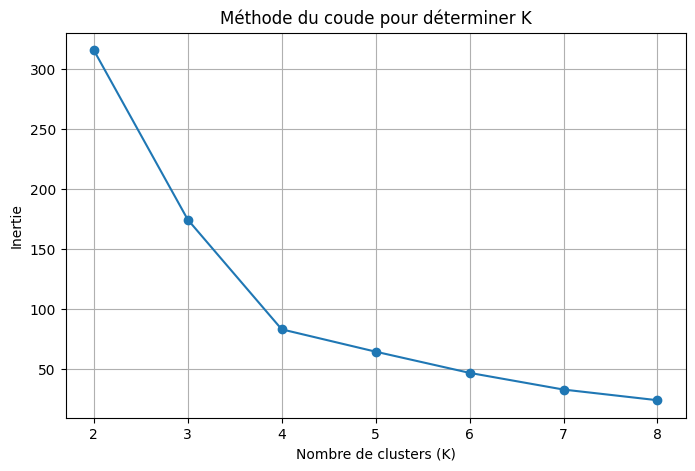

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertias,
    marker="o"
)

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude pour déterminer K")
plt.xticks(range(2, 9))
plt.grid()

plt.show()

In [19]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df_cluster["cluster"] = kmeans.fit_predict(X)

print(df_cluster.head())

             co2_per_capita  gdp_per_capita  co2_growth_prct  cluster
country                                                              
Afghanistan        0.145237     1290.350534        14.719417        0
Albania            1.282834     4867.277188        17.774723        0
Algeria            1.686868     6348.791123        16.913293        0
Angola             0.580528     2452.934398         9.169861        0
Argentina          2.448208    10278.998380         4.694810        0


In [20]:
print(df_cluster["cluster"].value_counts().sort_index())

cluster
0    120
1      4
2     38
3      2
Name: count, dtype: int64


In [21]:
cluster_profiles = df_cluster.groupby("cluster")[
    [
        "co2_per_capita",
        "gdp_per_capita",
        "co2_growth_prct"
    ]
].mean()

print(cluster_profiles)

         co2_per_capita  gdp_per_capita  co2_growth_prct
cluster                                                 
0              1.436033     4829.024024        31.698049
1             32.034504    46058.161248        79.275767
2              7.599620    18673.502980         9.630549
3              0.213175     3233.439316      1903.661199


In [22]:
df["coal_co2_per_capita"] = df["coal_co2"] / df["population"]

df["oil_co2_per_capita"] = df["oil_co2"] / df["population"]

In [23]:
print(df[
    [
        "co2_per_capita",
        "gdp_per_capita",
        "coal_co2_per_capita",
        "oil_co2_per_capita"
    ]
].isnull().sum())

co2_per_capita          213
gdp_per_capita         6405
coal_co2_per_capita    5012
oil_co2_per_capita      987
dtype: int64


In [24]:
cluster_vars = [
    "co2_per_capita",
    "gdp_per_capita",
    "oil_co2_per_capita"
]

df_cluster2 = df.groupby("country")[cluster_vars].mean()

print("Nombre de pays :", len(df_cluster2))
print("\nValeurs manquantes :")
print(df_cluster2.isnull().sum())

Nombre de pays : 215

Valeurs manquantes :
co2_per_capita         2
gdp_per_capita        51
oil_co2_per_capita     2
dtype: int64


In [25]:
print("Pays avant suppression :", len(df_cluster2))

df_cluster2 = df_cluster2.dropna()

print("Pays utilisés :", len(df_cluster2))

Pays avant suppression : 215
Pays utilisés : 164


In [26]:
print(df_cluster2.describe())

       co2_per_capita  gdp_per_capita  oil_co2_per_capita
count      164.000000      164.000000        1.640000e+02
mean         3.595572     9023.021462        1.538401e-06
std          5.799474     9165.077805        2.104210e-06
min          0.029977      800.117210        2.844823e-08
25%          0.456648     2459.488337        3.056646e-07
50%          1.657805     6353.961132        8.678805e-07
75%          4.049276    12354.504261        2.021410e-06
max         46.072883    65480.259183        1.641271e-05


In [27]:
print(df_cluster2.skew())

co2_per_capita        4.029585
gdp_per_capita        2.471345
oil_co2_per_capita    3.492779
dtype: float64


In [28]:
cluster_vars = [
    "co2_per_capita",
    "gdp_per_capita",
    "oil_co2_per_capita"
]

df_log = df_cluster2.copy()

for var in cluster_vars:
    df_log[var] = np.log1p(df_log[var])

print(df_log.describe())

       co2_per_capita  gdp_per_capita  oil_co2_per_capita
count      164.000000      164.000000        1.640000e+02
mean         1.108397        8.648253        1.538398e-06
std          0.841437        1.002280        2.104199e-06
min          0.029536        6.686007        2.844823e-08
25%          0.376004        7.808114        3.056646e-07
50%          0.977441        8.756991        8.678802e-07
75%          1.619244        9.421820        2.021408e-06
max          3.851697       11.089519        1.641258e-05


In [30]:
print(df_cluster2["oil_co2_per_capita"].head())
print(df_cluster2["oil_co2_per_capita"].describe())

country
Afghanistan    8.549914e-08
Albania        8.281302e-07
Algeria        5.827584e-07
Angola         2.850716e-07
Argentina      1.350190e-06
Name: oil_co2_per_capita, dtype: float64
count    1.640000e+02
mean     1.538401e-06
std      2.104210e-06
min      2.844823e-08
25%      3.056646e-07
50%      8.678805e-07
75%      2.021410e-06
max      1.641271e-05
Name: oil_co2_per_capita, dtype: float64


In [31]:
df["oil_share"] = df["oil_co2"] / df["co2"]

In [29]:
print(df_log.skew())

co2_per_capita        0.727294
gdp_per_capita       -0.084446
oil_co2_per_capita    3.492758
dtype: float64


In [32]:
print(df["oil_share"].describe())

count    18863.000000
mean         0.605443
std          0.354033
min          0.000000
25%          0.293562
50%          0.654974
75%          0.966338
max          1.000000
Name: oil_share, dtype: float64


In [33]:
print(df["oil_share"].isnull().sum())

924


In [34]:
cluster_vars = [
    "co2_per_capita",
    "gdp_per_capita",
    "oil_share"
]

df_cluster3 = df.groupby("country")[cluster_vars].mean()

print("Nombre de pays :", len(df_cluster3))
print(df_cluster3.isnull().sum())

Nombre de pays : 215
co2_per_capita     2
gdp_per_capita    51
oil_share          0
dtype: int64


In [35]:
df_cluster3 = df_cluster3.dropna()

print("Pays utilisés :", len(df_cluster3))

Pays utilisés : 164


In [36]:
print(df_cluster3.skew())

co2_per_capita    4.029585
gdp_per_capita    2.471345
oil_share        -0.131357
dtype: float64


In [37]:
df_cluster3_log = df_cluster3.copy()

df_cluster3_log["co2_per_capita"] = np.log1p(
    df_cluster3_log["co2_per_capita"]
)

df_cluster3_log["gdp_per_capita"] = np.log1p(
    df_cluster3_log["gdp_per_capita"]
)

print(df_cluster3_log.skew())

co2_per_capita    0.727294
gdp_per_capita   -0.084446
oil_share        -0.131357
dtype: float64


In [38]:
cluster_vars = [
    "co2_per_capita",
    "gdp_per_capita",
    "oil_share"
]

scaler = StandardScaler()

X = scaler.fit_transform(
    df_cluster3_log[cluster_vars]
)

print("Dimensions :", X.shape)

Dimensions : (164, 3)


In [39]:
inertias = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

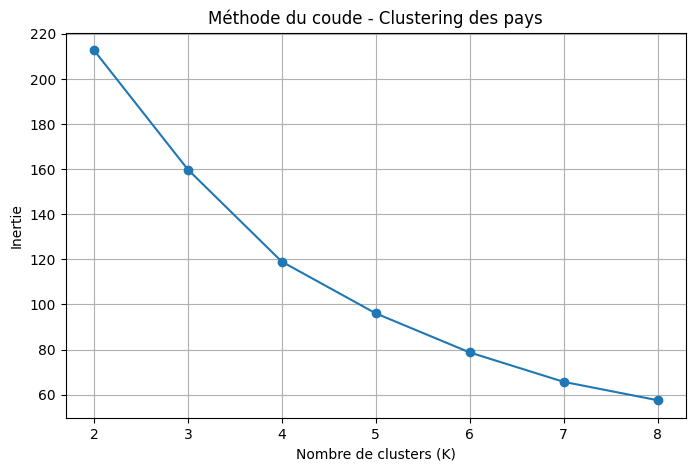

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertias,
    marker="o"
)

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude - Clustering des pays")
plt.xticks(range(2, 9))
plt.grid()

plt.show()

In [42]:
silhouette_scores = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X)
    
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

for k, score in zip(range(2, 9), silhouette_scores):
    print(f"K={k} : Silhouette Score = {score:.4f}")

K=2 : Silhouette Score = 0.4718
K=3 : Silhouette Score = 0.3725
K=4 : Silhouette Score = 0.3656
K=5 : Silhouette Score = 0.3727
K=6 : Silhouette Score = 0.3777
K=7 : Silhouette Score = 0.3843
K=8 : Silhouette Score = 0.3799


In [43]:
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df_cluster3["cluster"] = kmeans_final.fit_predict(X)

In [44]:
print(df_cluster3["cluster"].value_counts().sort_index())


cluster
0    37
1    43
2    42
3    42
Name: count, dtype: int64


In [45]:
cluster_profile = df_cluster3.groupby("cluster")[
    ["co2_per_capita", "gdp_per_capita", "oil_share"]
].mean()

print(cluster_profile)

         co2_per_capita  gdp_per_capita  oil_share
cluster                                           
0              1.563267     6350.501312   0.830522
1              2.338526     6737.546899   0.330771
2              0.230645     1670.314790   0.837897
3             10.037840    21069.981745   0.399094


In [46]:
for cluster in sorted(df_cluster3["cluster"].unique()):
    print(f"\n===== CLUSTER {cluster} =====")
    print(
        df_cluster3[
            df_cluster3["cluster"] == cluster
        ].index.tolist()
    )


===== CLUSTER 0 =====
['Albania', 'Azerbaijan', 'Barbados', 'Bolivia', 'Congo', 'Costa Rica', 'Cuba', 'Cyprus', 'Djibouti', 'Dominica', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eswatini', 'Guatemala', 'Indonesia', 'Iran', 'Iraq', 'Jamaica', 'Jordan', 'Lebanon', 'Malta', 'Mauritius', 'Mexico', 'Namibia', 'Palestine', 'Panama', 'Paraguay', 'Peru', 'Saint Lucia', 'Seychelles', 'Sri Lanka', 'Syria', 'Thailand', 'Uruguay']

===== CLUSTER 1 =====
['Algeria', 'Argentina', 'Armenia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Chile', 'China', 'Colombia', 'Croatia', 'Gabon', 'Georgia', 'Greece', 'Hungary', 'India', 'Kyrgyzstan', 'Lesotho', 'Malaysia', 'Moldova', 'Mongolia', 'Montenegro', 'Morocco', 'Nigeria', 'North Korea', 'North Macedonia', 'Pakistan', 'Philippines', 'Portugal', 'Romania', 'Serbia', 'South Africa', 'South Korea', 'Spain', 'Taiwan', 'Tajikistan', 'Tunisia', 'Turkey', 'Ukraine', 'Uzbekistan', 'Venezuela', 'Vietnam', 'Zimb

In [47]:
print(df_cluster3[["oil_share"]].describe())

        oil_share
count  164.000000
mean     0.590891
std      0.285249
min      0.043715
25%      0.330189
50%      0.591110
75%      0.875237
max      1.000000


In [49]:
print(
    df_cluster3[["oil_share"]]
    .sort_values("oil_share", ascending=False)
    .head(20)
)

                          oil_share
country                            
Comoros                    1.000000
Guinea-Bissau              1.000000
Gambia                     1.000000
Dominica                   1.000000
Palestine                  1.000000
Sao Tome and Principe      1.000000
Seychelles                 1.000000
Saint Lucia                1.000000
Central African Republic   0.996060
Mauritania                 0.982763
Guinea                     0.982411
Mali                       0.973453
Djibouti                   0.966458
Burundi                    0.958927
Nicaragua                  0.957999
Paraguay                   0.954601
Burkina Faso               0.946806
Liberia                    0.946758
Rwanda                     0.944707
Chad                       0.941674


In [51]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Variance expliquée par PC1 :", pca.explained_variance_ratio_[0])
print("Variance expliquée par PC2 :", pca.explained_variance_ratio_[1])
print("Variance totale expliquée :", pca.explained_variance_ratio_.sum())

Variance expliquée par PC1 : 0.7716553374162967
Variance expliquée par PC2 : 0.1976252916406248
Variance totale expliquée : 0.9692806290569215


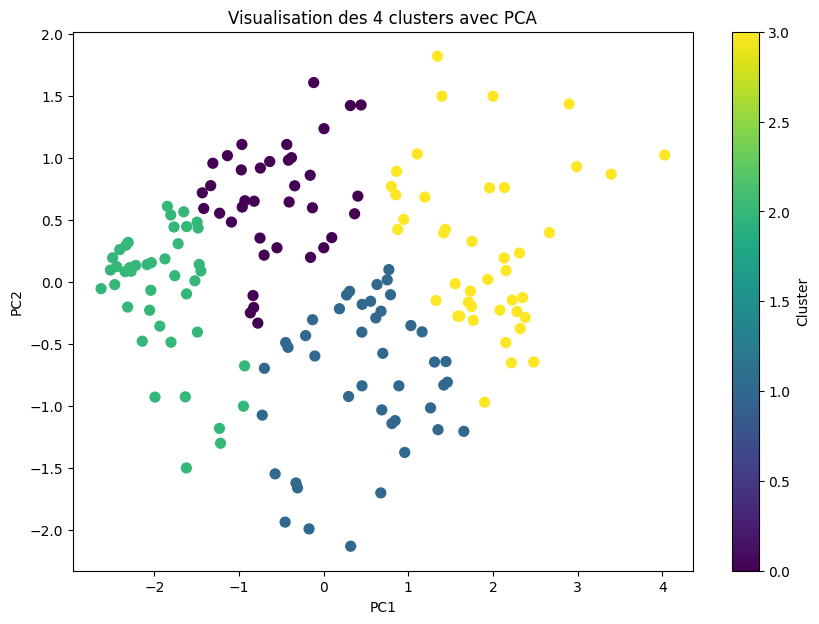

In [52]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df_cluster3["cluster"],
    cmap="viridis",
    s=50
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Visualisation des 4 clusters avec PCA")
plt.colorbar(label="Cluster")

plt.show()

In [53]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=["co2_per_capita", "gdp_per_capita", "oil_share"]
)

print(loadings.round(3))

                  PC1    PC2
co2_per_capita  0.626  0.268
gdp_per_capita  0.607  0.422
oil_share      -0.489  0.866
